<a href="https://colab.research.google.com/github/aditivaishnav0-netizen/Week8_lab/blob/main/DAproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from google.colab import files

uploaded = files.upload()

Saving WorldSustainabilityDataset.csv to WorldSustainabilityDataset.csv


In [5]:
import pandas as pd

filename = list(uploaded.keys())[0]

print("Uploaded filename:", filename)

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

display(df.head())

Uploaded filename: WorldSustainabilityDataset.csv
Dataset loaded successfully!
Dataset dimensions: (3287, 54)


,Country Name,Country Code,Year,Access to electricity (% of population) - EG.ELC.ACCS.ZS,Adjusted net national income per capita (annual % growth) - NY.ADJ.NNTY.PC.KD.ZG,"Adjusted net savings, excluding particulate emission damage (% of GNI) - NY.ADJ.SVNX.GN.ZS",Adjusted savings: carbon dioxide damage (% of GNI) - NY.ADJ.DCO2.GN.ZS,Adjusted savings: natural resources depletion (% of GNI) - NY.ADJ.DRES.GN.ZS,Adjusted savings: net forest depletion (% of GNI) - NY.ADJ.DFOR.GN.ZS,Adjusted savings: particulate emission damage (% of GNI) - NY.ADJ.DPEM.GN.ZS,...,Gini index (World Bank estimate) - SI.POV.GINI,Income Classification (World Bank Definition),Individuals using the Internet (% of population) - IT.NET.USER.ZS,"Life expectancy at birth, total (years) - SP.DYN.LE00.IN","Population, total - SP.POP.TOTL",Regime Type (RoW Measure Definition),Rural population (% of total population) - SP.RUR.TOTL.ZS,Total natural resources rents (% of GDP) - NY.GDP.TOTL.RT.ZS,Urban population (% of total population) - SP.URB.TOTL.IN.ZS,World Regions (UN SDG Definition)
0,Aruba,ABW,2000,91.660398,NaN,15.392211,2.389134,0.000190,0.000190,NaN,...,NaN,High income,NaN,NaN,NaN,NaN,53.283,NaN,NaN,Latin America and Caribbean
1,Aruba,ABW,2001,100.000000,NaN,11.491930,2.509046,0.000214,0.000214,NaN,...,NaN,High income,17.1,73.853,92892.0,NaN,53.661,0.000712,46.339,Latin America and Caribbean
2,Aruba,ABW,2002,100.000000,NaN,3.893620,2.721385,0.000223,0.000223,NaN,...,NaN,High income,18.8,73.937,94992.0,NaN,54.028,0.000657,45.972,Latin America and Caribbean
3,Aruba,ABW,2003,100.000000,NaN,6.713863,2.733676,0.000243,0.000243,NaN,...,NaN,High income,20.8,74.038,97016.0,NaN,54.394,0.000700,45.606,Latin America and Caribbean
4,Aruba,ABW,2004,100.000000,NaN,9.801576,2.678363,0.000256,0.000256,NaN,...,NaN,High income,23.0,74.156,98744.0,NaN,54.760,0.000685,45.240,Latin America and Caribbean


In [6]:
print("COLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

COLUMN NAMES:
['Country Name', 'Country Code', 'Year', 'Access to electricity (% of population) - EG.ELC.ACCS.ZS', 'Adjusted net national income per capita (annual % growth) - NY.ADJ.NNTY.PC.KD.ZG', 'Adjusted net savings, excluding particulate emission damage (% of GNI) - NY.ADJ.SVNX.GN.ZS', 'Adjusted savings: carbon dioxide damage (% of GNI) - NY.ADJ.DCO2.GN.ZS', 'Adjusted savings: natural resources depletion (% of GNI) - NY.ADJ.DRES.GN.ZS', 'Adjusted savings: net forest depletion (% of GNI) - NY.ADJ.DFOR.GN.ZS', 'Adjusted savings: particulate emission damage (% of GNI) - NY.ADJ.DPEM.GN.ZS', 'Automated teller machines (ATMs) (per 100,000 adults) - FB.ATM.TOTL.P5', 'Broad money (% of GDP) - FM.LBL.BMNY.GD.ZS', 'Children out of school (% of primary school age) - SE.PRM.UNER.ZS', 'Compulsory education, duration (years) - SE.COM.DURS', 'Cost of business start-up procedures, female (% of GNI per capita) - IC.REG.COST.PC.FE.ZS', 'Cost of business start-up procedures, male (% of GNI per capi

In [7]:
# Select the exact columns
rent_col = 'Total natural resources rents (% of GDP) - NY.GDP.TOTL.RT.ZS'
inflation_col = 'Inflation, consumer prices (annual %) - FP.CPI.TOTL.ZG'

# Filter the research period
period_df = df[
    (df['Year'] >= 2000) &
    (df['Year'] <= 2018)
].copy()

# Check the period and number of countries
print("Year range:", period_df['Year'].min(), "-", period_df['Year'].max())
print("Number of countries:", period_df['Country Name'].nunique())
print("Number of observations:", len(period_df))

# Count available years for each main variable
coverage = period_df.groupby('Country Name').agg(
    total_years=('Year', 'nunique'),
    rent_years=(rent_col, 'count'),
    inflation_years=(inflation_col, 'count')
)

print("\nCountry-level data coverage:")
display(coverage.head(15))

# Summary of coverage
print("\nCoverage summary:")
display(coverage.describe())

# Missing values within our research period
print("\nMissing values during 2000–2018:")
print(period_df[[rent_col, inflation_col]].isnull().sum())

# Check for repeated country-year combinations
print(
    "\nDuplicate country-year combinations:",
    period_df.duplicated(subset=['Country Name', 'Year']).sum()
)

Year range: 2000 - 2018
Number of countries: 173
Number of observations: 3287

Country-level data coverage:


,total_years,rent_years,inflation_years
Country Name,,,
Albania,19,18,19
Algeria,19,18,19
Angola,19,18,19
Antigua and Barbuda,19,18,19
Argentina,19,18,0
Armenia,19,18,19
Aruba,19,17,19
Australia,19,18,19
Austria,19,18,19



Coverage summary:


,total_years,rent_years,inflation_years
count,173.0,173.000000,173.000000
mean,19.0,17.647399,17.820809
std,0.0,1.969965,3.848471
min,19.0,0.000000,0.000000
25%,19.0,18.000000,19.000000
50%,19.0,18.000000,19.000000
75%,19.0,18.000000,19.000000
max,19.0,18.000000,19.000000



Missing values during 2000–2018:
Total natural resources rents (% of GDP) - NY.GDP.TOTL.RT.ZS    234
Inflation, consumer prices (annual %) - FP.CPI.TOTL.ZG          204
dtype: int64

Duplicate country-year combinations: 0


In [8]:
# Calculate country-level measures for 2000–2018
country_data = period_df.groupby('Country Name').agg(
    average_resource_rents=(rent_col, 'mean'),
    inflation_volatility=(inflation_col, 'std'),
    rent_years=(rent_col, 'count'),
    inflation_years=(inflation_col, 'count')
).reset_index()

# Keep countries with at least 15 valid years for BOTH variables
analysis_df = country_data[
    (country_data['rent_years'] >= 15) &
    (country_data['inflation_years'] >= 15)
].copy()

# Display results
print("Countries before coverage requirement:", len(country_data))
print("Countries retained:", len(analysis_df))
print("Countries excluded:", len(country_data) - len(analysis_df))

print("\nAnalytical dataset:")
display(analysis_df.head(10))

print("\nSummary statistics:")
display(
    analysis_df[
        ['average_resource_rents', 'inflation_volatility']
    ].describe().round(2)
)

print("\nCountries excluded:")
excluded = country_data[
    ~country_data['Country Name'].isin(analysis_df['Country Name'])
]
display(excluded)

Countries before coverage requirement: 173
Countries retained: 155
Countries excluded: 18

Analytical dataset:


,Country Name,average_resource_rents,inflation_volatility,rent_years,inflation_years
0,Albania,1.617920,2.278345,18,19
1,Algeria,25.018903,1.952654,18,19
2,Angola,32.783457,77.914554,18,19
3,Antigua and Barbuda,0.000000,1.400532,18,19
5,Armenia,0.686634,2.923284,18,19
6,Aruba,0.001626,2.804762,17,19
7,Australia,5.043924,0.963096,18,19
8,Austria,0.183165,0.730591,18,19
9,Azerbaijan,29.214603,5.788603,18,19
10,"Bahamas, The",0.011248,1.005746,18,19



Summary statistics:


,average_resource_rents,inflation_volatility
count,155.00,155.00
mean,6.75,5.47
std,10.04,13.54
min,0.00,0.62
25%,0.42,1.77
50%,1.89,2.78
75%,8.80,4.46
max,48.20,144.45



Countries excluded:


,Country Name,average_resource_rents,inflation_volatility,rent_years,inflation_years
4,Argentina,3.572576,NaN,18,0
16,Belize,2.633598,NaN,18,0
20,Bosnia and Herzegovina,1.750458,2.736584,18,13
36,Comoros,1.715838,2.592407,18,13
42,Cuba,2.164231,NaN,18,0
51,Equatorial Guinea,34.940961,2.361936,13,19
52,Eritrea,5.599256,NaN,11,0
85,"Korea, Dem. People's Rep.",NaN,NaN,0,0
91,Lebanon,0.001677,3.276048,18,10
108,Montenegro,0.776647,2.398275,18,13


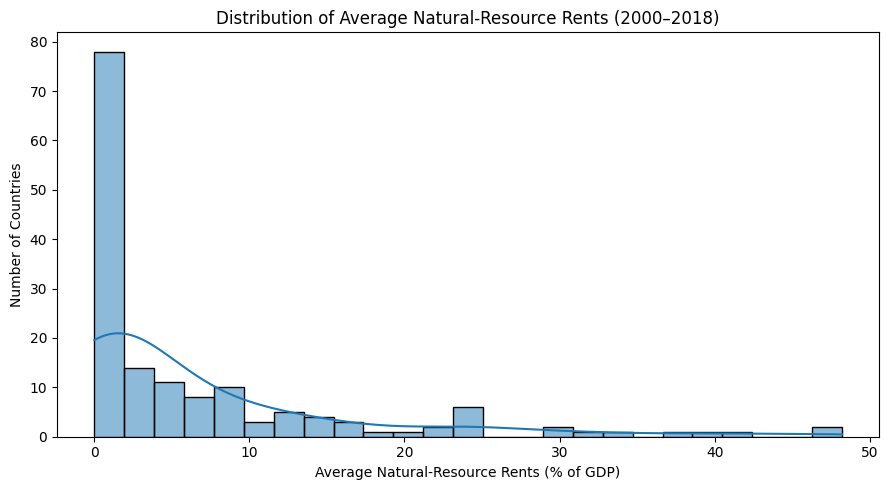

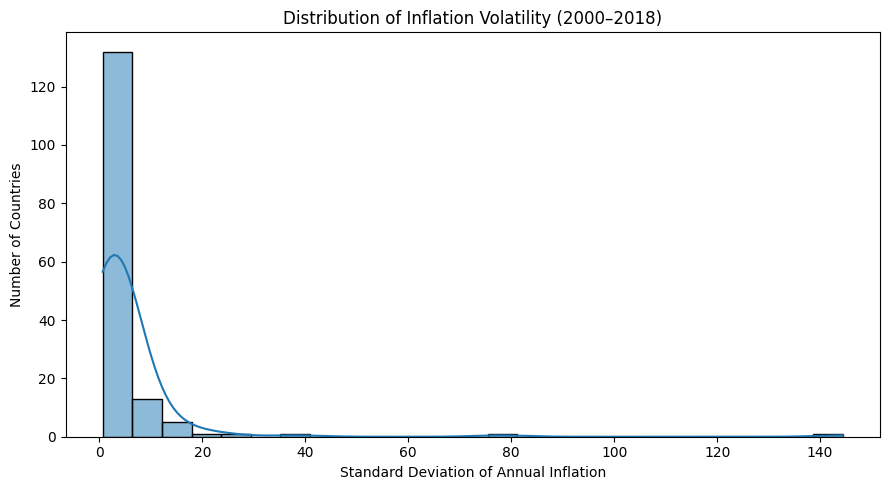

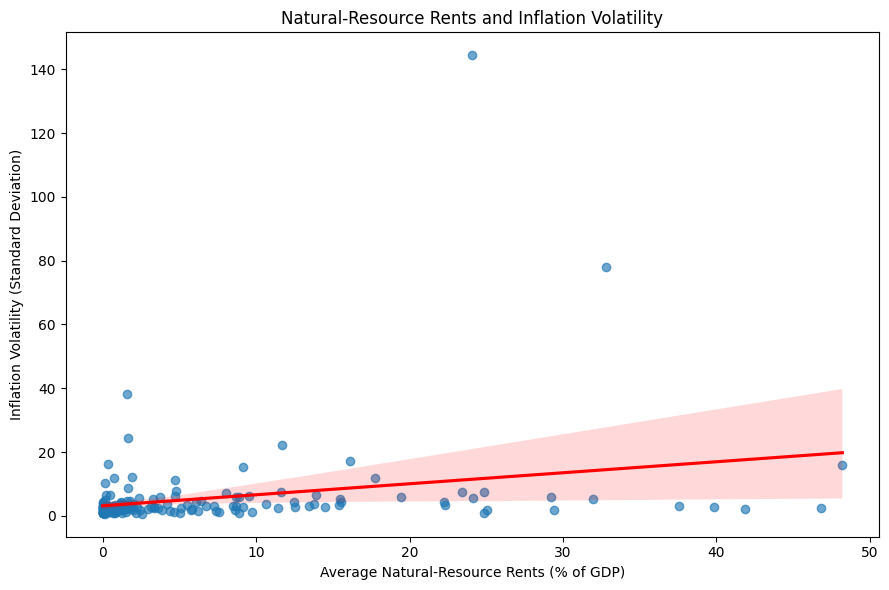

Top 10 Countries by Inflation Volatility:


,Country Name,average_resource_rents,inflation_volatility
37,"Congo, Dem. Rep.",24.09,144.45
2,Angola,32.78,77.91
14,Belarus,1.58,38.27
135,Serbia,1.68,24.49
48,Ecuador,11.69,22.25
147,Suriname,16.13,17.33
159,Turkey,0.35,16.11
76,Iraq,48.20,15.85
111,Myanmar,9.17,15.21
130,Romania,1.89,12.17


Correlation matrix:


,average_resource_rents,inflation_volatility
average_resource_rents,1.000,0.256
inflation_volatility,0.256,1.000


In [9]:

# 1. Distribution of average natural-resource rents
plt.figure(figsize=(9, 5))
sns.histplot(
    data=analysis_df,
    x='average_resource_rents',
    bins=25,
    kde=True
)
plt.title('Distribution of Average Natural-Resource Rents (2000–2018)')
plt.xlabel('Average Natural-Resource Rents (% of GDP)')
plt.ylabel('Number of Countries')
plt.tight_layout()
plt.show()


# 2. Distribution of inflation volatility
plt.figure(figsize=(9, 5))
sns.histplot(
    data=analysis_df,
    x='inflation_volatility',
    bins=25,
    kde=True
)
plt.title('Distribution of Inflation Volatility (2000–2018)')
plt.xlabel('Standard Deviation of Annual Inflation')
plt.ylabel('Number of Countries')
plt.tight_layout()
plt.show()


# 3. Relationship between resource rents and inflation volatility
plt.figure(figsize=(9, 6))
sns.regplot(
    data=analysis_df,
    x='average_resource_rents',
    y='inflation_volatility',
    scatter_kws={'alpha': 0.65},
    line_kws={'color': 'red'}
)
plt.title('Natural-Resource Rents and Inflation Volatility')
plt.xlabel('Average Natural-Resource Rents (% of GDP)')
plt.ylabel('Inflation Volatility (Standard Deviation)')
plt.tight_layout()
plt.show()


# 4. Ten countries with highest inflation volatility
top_10 = analysis_df.nlargest(10, 'inflation_volatility')[
    ['Country Name', 'average_resource_rents', 'inflation_volatility']
]

print("Top 10 Countries by Inflation Volatility:")
display(top_10.round(2))


# 5. Correlation between the two variables
correlation = analysis_df[
    ['average_resource_rents', 'inflation_volatility']
].corr()

print("Correlation matrix:")
display(correlation.round(3))


In [10]:

# Regression: Resource rents and inflation volatility

import statsmodels.api as sm

# Independent variable
X = analysis_df[['average_resource_rents']]

# Dependent variable
y = analysis_df['inflation_volatility']

# Add constant
X = sm.add_constant(X)

# Fit OLS regression with HC3 robust standard errors
model = sm.OLS(y, X).fit(cov_type='HC3')

# Display regression results
print(model.summary())


                             OLS Regression Results                             
Dep. Variable:     inflation_volatility   R-squared:                       0.065
Model:                              OLS   Adj. R-squared:                  0.059
Method:                   Least Squares   F-statistic:                     2.756
Date:                  Tue, 24 Nov 2026   Prob (F-statistic):             0.0989
Time:                          16:25:29   Log-Likelihood:                -618.10
No. Observations:                   155   AIC:                             1240.
Df Residuals:                       153   BIC:                             1246.
Df Model:                             1                                         
Covariance Type:                    HC3                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const   

In [11]:

# Investigate influential observations

import statsmodels.api as sm

# Calculate influence statistics
influence = model.get_influence()

diagnostics = analysis_df[
    ['Country Name', 'average_resource_rents', 'inflation_volatility']
].copy()

diagnostics['cooks_distance'] = influence.cooks_distance[0]
diagnostics['studentized_residual'] = influence.resid_studentized_external
diagnostics['leverage'] = influence.hat_matrix_diag

# Common screening threshold for Cook's distance
cook_threshold = 4 / len(analysis_df)

print("Cook's distance screening threshold:", round(cook_threshold, 4))

print("\nTop 10 influential observations:")
display(
    diagnostics.sort_values(
        'cooks_distance', ascending=False
    ).head(10).round(3)
)

# Count observations exceeding the screening threshold
flagged = diagnostics[
    diagnostics['cooks_distance'] > cook_threshold
]

print("\nNumber of observations above the screening threshold:", len(flagged))
display(flagged.sort_values('cooks_distance', ascending=False))


# Sensitivity analysis: refit after excluding flagged observations
# This is a diagnostic comparison, not a recommendation to delete them.

sensitivity_df = analysis_df[
    ~analysis_df['Country Name'].isin(flagged['Country Name'])
].copy()

X_sens = sm.add_constant(
    sensitivity_df[['average_resource_rents']]
)

y_sens = sensitivity_df['inflation_volatility']

sensitivity_model = sm.OLS(y_sens, X_sens).fit(cov_type='HC3')

print("\nOriginal model:")
print("Coefficient:", round(model.params['average_resource_rents'], 4))
print("P-value:", round(model.pvalues['average_resource_rents'], 4))
print("R-squared:", round(model.rsquared, 4))

print("\nSensitivity model:")
print("Countries:", len(sensitivity_df))
print("Coefficient:", round(sensitivity_model.params['average_resource_rents'], 4))
print("P-value:", round(sensitivity_model.pvalues['average_resource_rents'], 4))
print("R-squared:", round(sensitivity_model.rsquared, 4))


Cook's distance screening threshold: 0.0258

Top 10 influential observations:


,Country Name,average_resource_rents,inflation_volatility,cooks_distance,studentized_residual,leverage
37,"Congo, Dem. Rep.",24.086,144.451,1.394,18.299,0.026
2,Angola,32.783,77.915,0.648,5.393,0.050
87,Kuwait,46.827,2.299,0.116,-1.376,0.110
38,"Congo, Rep.",41.850,2.140,0.071,-1.232,0.086
133,Saudi Arabia,39.810,2.787,0.052,-1.118,0.077
121,Oman,37.545,3.038,0.038,-1.030,0.068
14,Belarus,1.580,38.268,0.029,2.697,0.008
59,Gabon,29.413,1.932,0.016,-0.882,0.040
129,Qatar,31.933,5.282,0.012,-0.691,0.047
135,Serbia,1.679,24.491,0.010,1.596,0.008



Number of observations above the screening threshold: 7


,Country Name,average_resource_rents,inflation_volatility,cooks_distance,studentized_residual,leverage
37,"Congo, Dem. Rep.",24.085947,144.450581,1.394442,18.299307,0.025818
2,Angola,32.783457,77.914554,0.648339,5.392748,0.050126
87,Kuwait,46.826989,2.299052,0.116279,-1.376023,0.109956
38,"Congo, Rep.",41.850247,2.140204,0.070999,-1.231758,0.085846
133,Saudi Arabia,39.810436,2.787389,0.051925,-1.117539,0.076886
121,Oman,37.544668,3.037763,0.038408,-1.029843,0.067562
14,Belarus,1.579819,38.268405,0.028803,2.697374,0.008175



Original model:
Coefficient: 0.3452
P-value: 0.0969
R-squared: 0.0654

Sensitivity model:
Countries: 148
Coefficient: 0.1443
P-value: 0.0029
R-squared: 0.0888


In [12]:

# Log-transformed inflation volatility robustness check

import numpy as np
import statsmodels.api as sm

# Create transformed dependent variable
analysis_df['log_inflation_volatility'] = np.log1p(
    analysis_df['inflation_volatility']
)

# Independent variable
X_log = sm.add_constant(
    analysis_df[['average_resource_rents']]
)

# Dependent variable
y_log = analysis_df['log_inflation_volatility']

# Run regression with HC3 robust standard errors
log_model = sm.OLS(y_log, X_log).fit(cov_type='HC3')

print(log_model.summary())


                               OLS Regression Results                               
Dep. Variable:     log_inflation_volatility   R-squared:                       0.101
Model:                                  OLS   Adj. R-squared:                  0.095
Method:                       Least Squares   F-statistic:                     7.271
Date:                      Tue, 24 Nov 2026   Prob (F-statistic):            0.00779
Time:                              16:27:04   Log-Likelihood:                -155.29
No. Observations:                       155   AIC:                             314.6
Df Residuals:                           153   BIC:                             320.7
Df Model:                                 1                                         
Covariance Type:                        HC3                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------

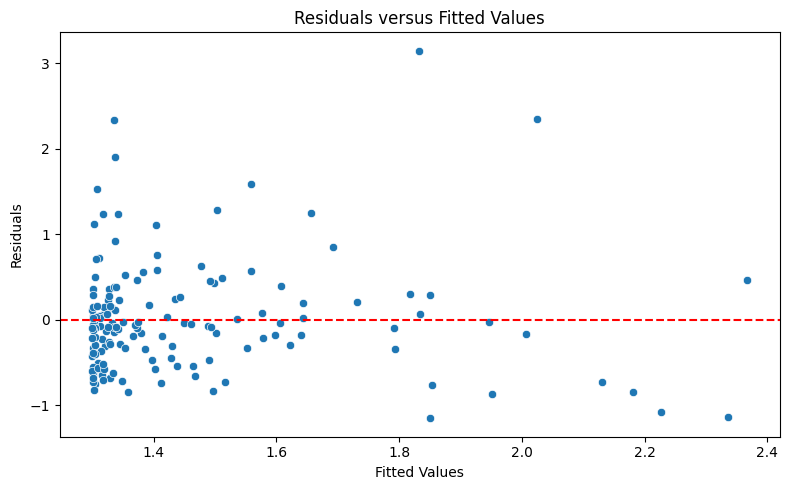

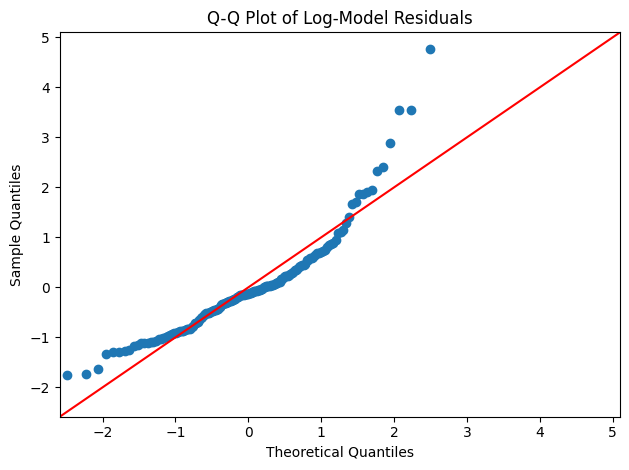

Breusch-Pagan test
LM statistic: 8.2104
P-value: 0.0042

Ramsey RESET test
<F test: F=5.152459788325439, p=0.024619375018727664, df_denom=152, df_num=1>

Spearman rank correlation
Correlation: 0.3767
P-value: 0.0


In [13]:

import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from statsmodels.stats.diagnostic import (
    het_breuschpagan,
    linear_reset
)
from scipy.stats import spearmanr

# 1. Residuals versus fitted values
fitted = log_model.fittedvalues
residuals = log_model.resid

plt.figure(figsize=(8, 5))
sns.scatterplot(x=fitted, y=residuals)
plt.axhline(0, linestyle='--', color='red')
plt.title('Residuals versus Fitted Values')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.tight_layout()
plt.show()

# 2. Q-Q plot
sm.qqplot(residuals, line='45', fit=True)
plt.title('Q-Q Plot of Log-Model Residuals')
plt.tight_layout()
plt.show()

# 3. Breusch-Pagan test for heteroskedasticity
bp_test = het_breuschpagan(residuals, log_model.model.exog)

print("Breusch-Pagan test")
print("LM statistic:", round(bp_test[0], 4))
print("P-value:", round(bp_test[1], 4))

# 4. Ramsey RESET test for possible functional-form problems
reset_test = linear_reset(
    log_model,
    power=2,
    use_f=True
)

print("\nRamsey RESET test")
print(reset_test)

# 5. Spearman rank correlation as an additional check
spearman_result = spearmanr(
    analysis_df['average_resource_rents'],
    analysis_df['inflation_volatility']
)

print("\nSpearman rank correlation")
print("Correlation:", round(spearman_result.statistic, 4))
print("P-value:", round(spearman_result.pvalue, 4))


In [14]:

# Quadratic regression to investigate nonlinearity

analysis_df['resource_rents_squared'] = (
    analysis_df['average_resource_rents'] ** 2
)

X_quad = analysis_df[
    ['average_resource_rents', 'resource_rents_squared']
]

X_quad = sm.add_constant(X_quad)

y = analysis_df['log_inflation_volatility']

quadratic_model = sm.OLS(y, X_quad).fit(cov_type='HC3')

print(quadratic_model.summary())


                               OLS Regression Results                               
Dep. Variable:     log_inflation_volatility   R-squared:                       0.131
Model:                                  OLS   Adj. R-squared:                  0.119
Method:                       Least Squares   F-statistic:                     6.268
Date:                      Tue, 24 Nov 2026   Prob (F-statistic):            0.00242
Time:                              16:28:35   Log-Likelihood:                -152.71
No. Observations:                       155   AIC:                             311.4
Df Residuals:                           152   BIC:                             320.5
Df Model:                                 2                                         
Covariance Type:                        HC3                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------

In [15]:

print("Log-linear model")
print("AIC:", log_model.aic)
print("BIC:", log_model.bic)

print("\nQuadratic model")
print("AIC:", quadratic_model.aic)
print("BIC:", quadratic_model.bic)


Log-linear model
AIC: 314.58155673006684
BIC: 320.66840696390534

Quadratic model
AIC: 311.4144930419942
BIC: 320.54476839275196


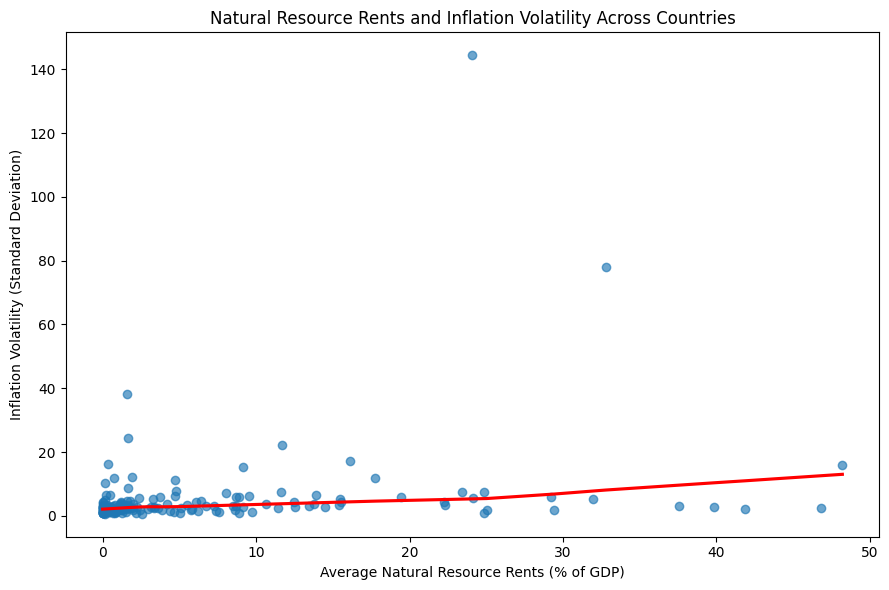

In [16]:

plt.figure(figsize=(9, 6))

sns.regplot(
    data=analysis_df,
    x='average_resource_rents',
    y='inflation_volatility',
    lowess=True,
    scatter_kws={'alpha': 0.65},
    line_kws={'color': 'red'}
)

plt.title(
    'Natural Resource Rents and Inflation Volatility Across Countries'
)
plt.xlabel('Average Natural Resource Rents (% of GDP)')
plt.ylabel('Inflation Volatility (Standard Deviation)')
plt.tight_layout()
plt.show()
